The redesign already launched for all new accounts in one market, in week 104. There is no randomized holdout, and we have not yet established a suitable comparison market. ITS lets us compare activation with its earlier path. A randomized test would still be preferable for a future expansion where feasible.

One row represents a signup week: the percentage of that week's new accounts that activate within seven days. We have 104 weeks before launch and 52 after, all with complete follow-up. The case-study setup assumes comparable cohort sizes, consistent tracking, and no simultaneous product change.

Before modeling, agree on the target: activation for the 26th cohort after launch, roughly six months in. We are reviewing that point retrospectively using the full year of postlaunch data, not pretending all those data were available at six months. Suppose the PM considers a 1 percentage-point gain useful, provided retention and support contacts do not worsen. We will use a 5% significance level. These are choices for this example, not defaults for every ITS study.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.tsa.stattools import acf

# Recreate the same invented study in every cell; no earlier run is required.
# Each row is one signup cohort's seven-day activation rate, in percent.
rng = np.random.default_rng(17)
t = np.arange(156)
launch = 104
post = (t >= launch).astype(int)
after = np.maximum(t - launch, 0)

# Nearby weeks share some unexplained variation.
noise = rng.normal(0, 0.25, len(t))
error = np.zeros(len(t))
for k in range(1, len(t)):
    error[k] = 0.55 * error[k - 1] + noise[k]

# These are data-setup inputs, not quantities the analyst already knows.
season = 0.8 * np.sin(2 * np.pi * t / 52)
untreated = 40 + 0.04 * t + season
rate = untreated + 1.5 * post + 0.03 * after + error
weekly = pd.DataFrame({
    "week": t, "post": post, "after": after,
    "sin": np.sin(2 * np.pi * t / 52),
    "cos": np.cos(2 * np.pi * t / 52),
    "rate": rate,
})

#### Inspect the data and validate the earlier trend
First, make sure each week has a usable rate and plot the history. A rising or seasonal baseline can make a simple before-and-after average exaggerate the improvement.

Then ask a harder question: can the earlier trend predict weeks it has not seen? Train on the first 78 weeks and predict the next 26, all before launch. We include a straight trend and a smooth annual cycle. If that forecast misses badly, revise the comparison before interpreting a launch effect.

156 consecutive cohort-weeks; no missing values.

Rows around launch (post: 0 = old flow, 1 = redesign):
 week  post  after   rate
  101     0      0 44.282
  102     0      0 44.304
  103     0      0 44.360
  104     1      0 46.169
  105     1      1 46.156
  106     1      2 46.219


,Quantity,Value
0,Prelaunch average (%),41.994
1,Postlaunch average (%),47.510
2,Raw before/after difference (pp),5.515
3,Prelaunch forecast RMSE (pp),0.341


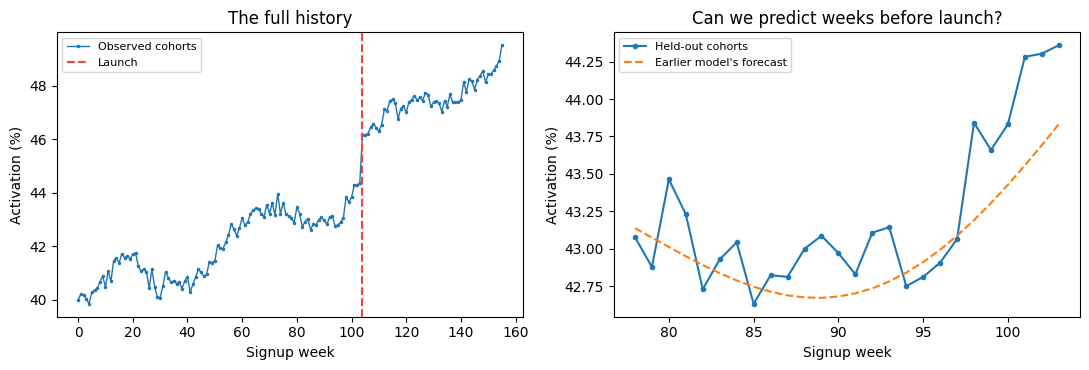

In [2]:
# Check the time index and outcomes before fitting anything.
assert weekly.week.is_unique
assert np.all(np.diff(weekly.week) == 1)
assert weekly.notna().all().all()
assert weekly.rate.between(0, 100).all()
print("156 consecutive cohort-weeks; no missing values.")
print("\nRows around launch (post: 0 = old flow, 1 = redesign):")
print(weekly.loc[101:106, ["week", "post", "after", "rate"]]
      .round(3).to_string(index=False))

# Forecast the final 26 PRE-launch weeks using only the earlier 78.
# Keep this validation period out of training.
training = weekly.iloc[:78]
validation = weekly.iloc[78:104]
pre_fit = smf.ols("rate ~ week + sin + cos", data=training).fit()
forecast = pre_fit.predict(validation)
validation_rmse = np.sqrt(np.mean((validation.rate - forecast) ** 2))
before = weekly.loc[weekly.post == 0, "rate"].mean()
after_mean = weekly.loc[weekly.post == 1, "rate"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(weekly.week, weekly.rate, ".-", markersize=3,
             linewidth=1, label="Observed cohorts")
axes[0].axvline(launch, color="#ef4444", linestyle="--", label="Launch")
axes[0].set(xlabel="Signup week", ylabel="Activation (%)",
            title="The full history")
axes[0].legend(fontsize=8)
axes[1].plot(validation.week, validation.rate, ".-", label="Held-out cohorts")
axes[1].plot(validation.week, forecast, "--", label="Earlier model's forecast")
axes[1].set(xlabel="Signup week", ylabel="Activation (%)",
            title="Can we predict weeks before launch?")
axes[1].legend(fontsize=8)
fig.tight_layout()

pd.DataFrame({
    "Quantity": ["Prelaunch average (%)", "Postlaunch average (%)",
                 "Raw before/after difference (pp)",
                 "Prelaunch forecast RMSE (pp)"],
    "Value": [before, after_mean, after_mean - before, validation_rmse],
}).round(3)

In the default output, activation averages 41.994% before and 47.510% after, a raw increase of 5.515 percentage points. But the history was already rising and moving through a seasonal cycle. That entire increase cannot be credited to onboarding.

The held-out forecast has an error of 0.341 percentage points, measured by root mean squared error, or RMSE. It summarizes how far the predictions miss the observed weekly rates. The plotted forecast follows the earlier pattern reasonably well, so we will keep this baseline for the example. This is a forecast check, not a confidence interval or proof that nothing else changed at launch.

#### Separate the launch effect from the earlier trend
Now fit the segmented regression from the introduction. week captures the earlier trend, post allows an immediate jump, and after allows growth to change after launch. The sin and cos terms describe the annual cycle.

Nearby weeks can share outages, campaigns, or other fluctuations. We use HAC standard errors to allow for some of that dependence when calculating uncertainty. We start with four weekly lags and check that choice in the next step. HAC changes the uncertainty calculation, not the fitted line.

                            OLS Regression Results                            
Dep. Variable:                   rate   R-squared:                       0.991
Model:                            OLS   Adj. R-squared:                  0.990
Method:                 Least Squares   F-statistic:                     1711.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):          2.60e-130
Time:                        17:57:15   Log-Likelihood:                -19.090
No. Observations:                 156   AIC:                             50.18
Df Residuals:                     150   BIC:                             68.48
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     39.7895      0.092    434.220      0.0

,Quantity,Estimate
0,Immediate change (pp),1.441
1,Extra growth (pp/week),0.029
2,Change at 26th postlaunch cohort (pp),2.161


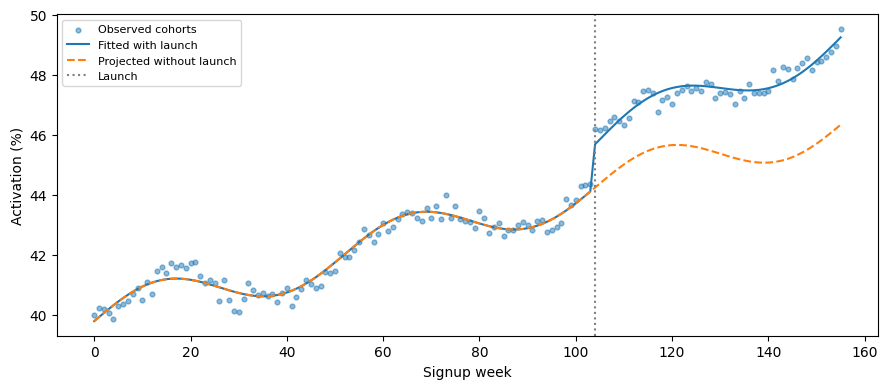

In [3]:
# Allow the launch to change both activation immediately and its growth rate.
# Sine/cosine keep the annual seasonal pattern in the comparison.
formula = "rate ~ week + post + after + sin + cos"

# Weekly errors may move together. HAC adjusts uncertainty for dependence.
# Four lags is our starting choice for this example, not a universal rule.
fit = smf.ols(formula, data=weekly).fit(
    cov_type="HAC", cov_kwds={"maxlags": 4}, use_t=False)
print(fit.summary(alpha=0.05))

# Project the same calendar weeks without either launch-related change.
no_launch = weekly.assign(post=0, after=0)
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(weekly.week, weekly.rate, s=12, alpha=0.5, label="Observed cohorts")
ax.plot(weekly.week, fit.predict(weekly), label="Fitted with launch")
ax.plot(weekly.week, fit.predict(no_launch), "--", label="Projected without launch")
ax.axvline(launch, color="gray", linestyle=":", label="Launch")
ax.set(xlabel="Signup week", ylabel="Activation (%)")
ax.legend(fontsize=8)
fig.tight_layout()

# At the 26th postlaunch cohort, 25 weeks have elapsed since week 104.
# Use full-precision coefficients, not the rounded numbers in the table.
elapsed = 25
horizon_effect = fit.params["post"] + elapsed * fit.params["after"]
pd.DataFrame({
    "Quantity": ["Immediate change (pp)", "Extra growth (pp/week)",
                 "Change at 26th postlaunch cohort (pp)"],
    "Estimate": [fit.params["post"], fit.params["after"], horizon_effect],
}).round(3)

The post coefficient estimates an immediate gain of 1.441 percentage points. The after coefficient adds 0.029 points per week to the earlier growth rate. At our 26th postlaunch cohort, 25 weeks have elapsed, giving an estimated 2.161-point gain. The code uses unrounded coefficients for that calculation.

Read the rest of the table too. The week coefficient says activation was already growing by about 0.043 points per week. The seasonal terms keep the annual pattern in the comparison. Do not remove the cosine term just because its p-value is large; we specified the seasonal pair to represent that cycle.

The model fits 156 weekly cohorts, not 156 people. Its R² of 0.991 describes how closely the fitted values track the observed rates. The overall F-test asks whether the predictors jointly add information beyond an intercept. Neither tells us that onboarding caused the change.

The coefficient table gives each term's standard error, p-value, and interval. A displayed 0.000 is rounding, not a probability of exactly zero. Our decision depends on the combined effect at week 129, so we still need an interval and test for post + 25 × after, not just for the immediate jump.

#### Check the model and report the result
Before recommending expansion, look at what the model leaves unexplained. These differences are called residuals. If neighboring weeks move together, treating them as independent can make us too confident.

Plot the residuals and measure their correlation across weeks. Then calculate the same six-month effect using HAC allowances of one, four, and eight weeks. If the conclusion changes materially, investigate rather than selecting the most favorable result.

Residual correlation one week apart: 0.387

Same effect, different dependence allowances:
 HAC lags  Effect (pp)  SE (pp)  95% low  95% high   p-value
        1        2.161    0.096    1.973     2.350 1.72e-111
        4        2.161    0.107    1.951     2.372  3.50e-90
        8        2.161    0.095    1.976     2.347 1.90e-115


,Final result,Value
0,Outcome,Seven-day activation
1,Decision horizon,26th postlaunch cohort (week 129)
2,Cohort-weeks fitted,156
3,Estimated gain,2.161 pp
4,Standard error,0.107 pp
5,95% confidence interval,1.951 to 2.372 pp
6,p-value: no effect,3.50e-90
7,Significance level,0.05
8,Minimum useful gain,1.0 pp


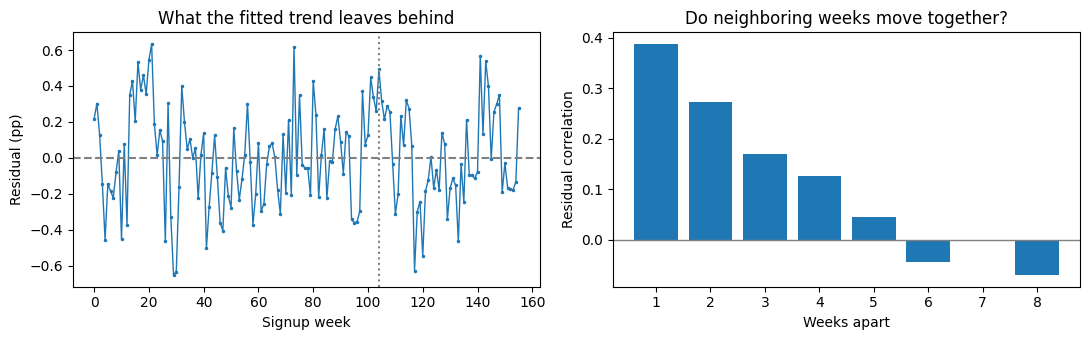

In [4]:
formula = "rate ~ week + post + after + sin + cos"
fit = smf.ols(formula, data=weekly).fit(
    cov_type="HAC", cov_kwds={"maxlags": 4}, use_t=False)

# Residuals are the weekly outcomes minus their fitted values.
# Correlation at lag 1 compares each error with the previous week's error.
correlations = acf(fit.resid, nlags=8)
print(f"Residual correlation one week apart: {correlations[1]:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(weekly.week, fit.resid, ".-", markersize=3, linewidth=1)
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].axvline(launch, color="gray", linestyle=":")
axes[0].set(xlabel="Signup week", ylabel="Residual (pp)",
            title="What the fitted trend leaves behind")
axes[1].bar(np.arange(1, 9), correlations[1:])
axes[1].axhline(0, color="gray", linewidth=1)
axes[1].set(xlabel="Weeks apart", ylabel="Residual correlation",
            title="Do neighboring weeks move together?")
fig.tight_layout()

# Test ONE decision-relevant effect: post + 25 * after.
# This combines both coefficients and their covariance.
contrast = np.zeros(len(fit.params))
contrast[fit.params.index.get_loc("post")] = 1
contrast[fit.params.index.get_loc("after")] = 25

# Keep the outcome model fixed; vary the HAC lag allowance.
# Do not select the lag giving the smallest p-value.
rows = []
for lag in [1, 4, 8]:
    sensitivity_fit = smf.ols(formula, data=weekly).fit(
        cov_type="HAC", cov_kwds={"maxlags": lag}, use_t=False)
    test = sensitivity_fit.t_test(contrast)
    low, high = test.conf_int(alpha=0.05)[0]
    rows.append({
        "HAC lags": lag,
        "Effect (pp)": float(np.asarray(test.effect).item()),
        "SE (pp)": float(np.asarray(test.sd).item()),
        "95% low": low, "95% high": high,
        "p-value": f"{float(np.asarray(test.pvalue).item()):.2e}",
    })
print("\nSame effect, different dependence allowances:")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Report the prespecified four-lag result, not the most favorable variant.
final_test = fit.t_test(contrast)
effect = float(np.asarray(final_test.effect).item())
se = float(np.asarray(final_test.sd).item())
low, high = final_test.conf_int(alpha=0.05)[0]
p_value = float(np.asarray(final_test.pvalue).item())
meaningful_gain = 1.0
pd.DataFrame({
    "Final result": ["Outcome", "Decision horizon", "Cohort-weeks fitted",
                     "Estimated gain", "Standard error", "95% confidence interval",
                     "p-value: no effect", "Significance level",
                     "Minimum useful gain"],
    "Value": ["Seven-day activation", "26th postlaunch cohort (week 129)",
              str(len(weekly)), f"{effect:.3f} pp", f"{se:.3f} pp",
              f"{low:.3f} to {high:.3f} pp", f"{p_value:.2e}", "0.05",
              f"{meaningful_gain:.1f} pp"],
})

Errors one week apart have a correlation of 0.387, so there is still a pattern in neighboring weeks. HAC allows for this dependence; it does not remove it. The plot does not show an obvious large remaining trend, but the dependence is why ordinary independent-error standard errors would be a poor default here.

Across the three lag choices, the estimated effect stays at 2.161 points. Its 95% intervals run from 1.973–2.350, 1.951–2.372, and 1.976–2.347 points. All remain above our 1-point business threshold. Longer lag allowances do not always produce wider intervals. These checks support the uncertainty choice in this example; they do not test for a second launch or a changed customer mix.

What did we find? Using the planned four-lag result, activation for the 26th postlaunch cohort is an estimated 2.161 percentage points higher than the projected no-launch path. The standard error is 0.107 points, and the 95% confidence interval is 1.951 to 2.372 points.

Is it statistically significant? Yes, under this model: the p-value for no effect at that horizon is 3.50 × 10−90, below 0.05. Such a large fitted gap relative to its standard error would be very unusual under a zero-effect model. This is a deliberately clean worked example, not a realistic promise of that precision in every study or proof of causality.

What should we do? The estimated gain clears the 1-point threshold, which makes expansion worth testing. I would first check the release calendar, acquisition mix, and tracking history; those checks cannot be completed from these rate-only data. Retention and support outcomes are also missing. If those checks support the comparison and guardrails are acceptable, run a limited randomized expansion before committing to a broad rollout. This study estimates a gain for one market at one horizon, not every future cohort or market.